# 🌸 Task 1: Iris Flower Classification

**Objective:** Train a machine learning classification model to identify the species of an iris flower  
(*Setosa*, *Versicolor*, or *Virginica*) from its physical measurements.

**Tech Stack:** Python · scikit-learn · pandas · matplotlib · seaborn

---

### 📋 Table of Contents
1. Import Libraries & Load Data
2. Exploratory Data Analysis (EDA)
3. Data Visualisation
4. Feature Selection Discussion
5. Data Splitting
6. Model Training & Evaluation
7. Model Comparison & Best Model Declaration

---

## 1. 📦 Import Libraries & Load Dataset

In [1]:
# === Core Libraries ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# === scikit-learn Modules ===
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# === Configuration ===
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='husl', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 120
plt.rcParams['font.family'] = 'sans-serif'

print("✅ All libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


✅ All libraries imported successfully!


In [2]:
# --- Load the Iris dataset from scikit-learn ---
iris = load_iris()

# Create a clean DataFrame for analysis
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)

print(f"📊 Dataset loaded: {df.shape[0]} samples × {df.shape[1]} columns")
df.head(10)

📊 Dataset loaded: 150 samples × 5 columns

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


## 2. 🔍 Exploratory Data Analysis (EDA)

### 2.1 Dataset Shape & Structure

In [3]:
print(f"{'─'*50}")
print(f"  📐 Shape      :  {df.shape[0]} rows × {df.shape[1]} columns")
print(f"  🧩 Features   :  {len(iris.feature_names)}")
print(f"  🏷️  Classes    :  {list(iris.target_names)}")
print(f"{'─'*50}")

──────────────────────────────────────────────────
  📐 Shape      :  150 rows × 5 columns
  🧩 Features   :  4
  🏷️  Classes    :  [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
──────────────────────────────────────────────────


In [4]:
# --- Data Types ---
print("📋 Column Data Types:\n")
print(df.dtypes)

📋 Column Data Types:

sepal length (cm)     float64
sepal width (cm)      float64
petal length (cm)     float64
petal width (cm)      float64
species              category
dtype: object


In [5]:
# --- Null Value Check ---
print("🔎 Null Values per Column:\n")
print(df.isnull().sum())
print(f"\n{'─'*40}")
print(f"  Total Null Values: {df.isnull().sum().sum()}")
print(f"{'─'*40}")

🔎 Null Values per Column:

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

────────────────────────────────────────
  Total Null Values: 0
────────────────────────────────────────


> ✅ **Observation:** The dataset is perfectly clean — no missing values were found. This is expected since it's a curated benchmark dataset.

In [6]:
# --- Descriptive Statistics ---
print("📊 Descriptive Statistics:\n")
df.describe().round(2)

📊 Descriptive Statistics:



,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


> **Key Observations from Descriptive Statistics:**
> - **Sepal length** ranges from 4.3 cm to 7.9 cm (mean ≈ 5.84 cm)
> - **Petal length** has the widest variation (1.0 – 6.9 cm), suggesting high discriminative power
> - **Petal width** also shows strong variation (0.1 – 2.5 cm)
> - Standard deviations indicate sepal features are more tightly clustered than petal features

In [7]:
# --- Class Distribution ---
print("🏷️ Species Distribution:\n")
species_counts = df['species'].value_counts()
print(species_counts)
print(f"\n✅ Dataset is perfectly balanced: {species_counts.values[0]} samples per class")

🏷️ Species Distribution:

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

✅ Dataset is perfectly balanced: 50 samples per class


## 3. 📊 Data Visualisation

### 3.1 Pairplot — Feature Distributions by Species

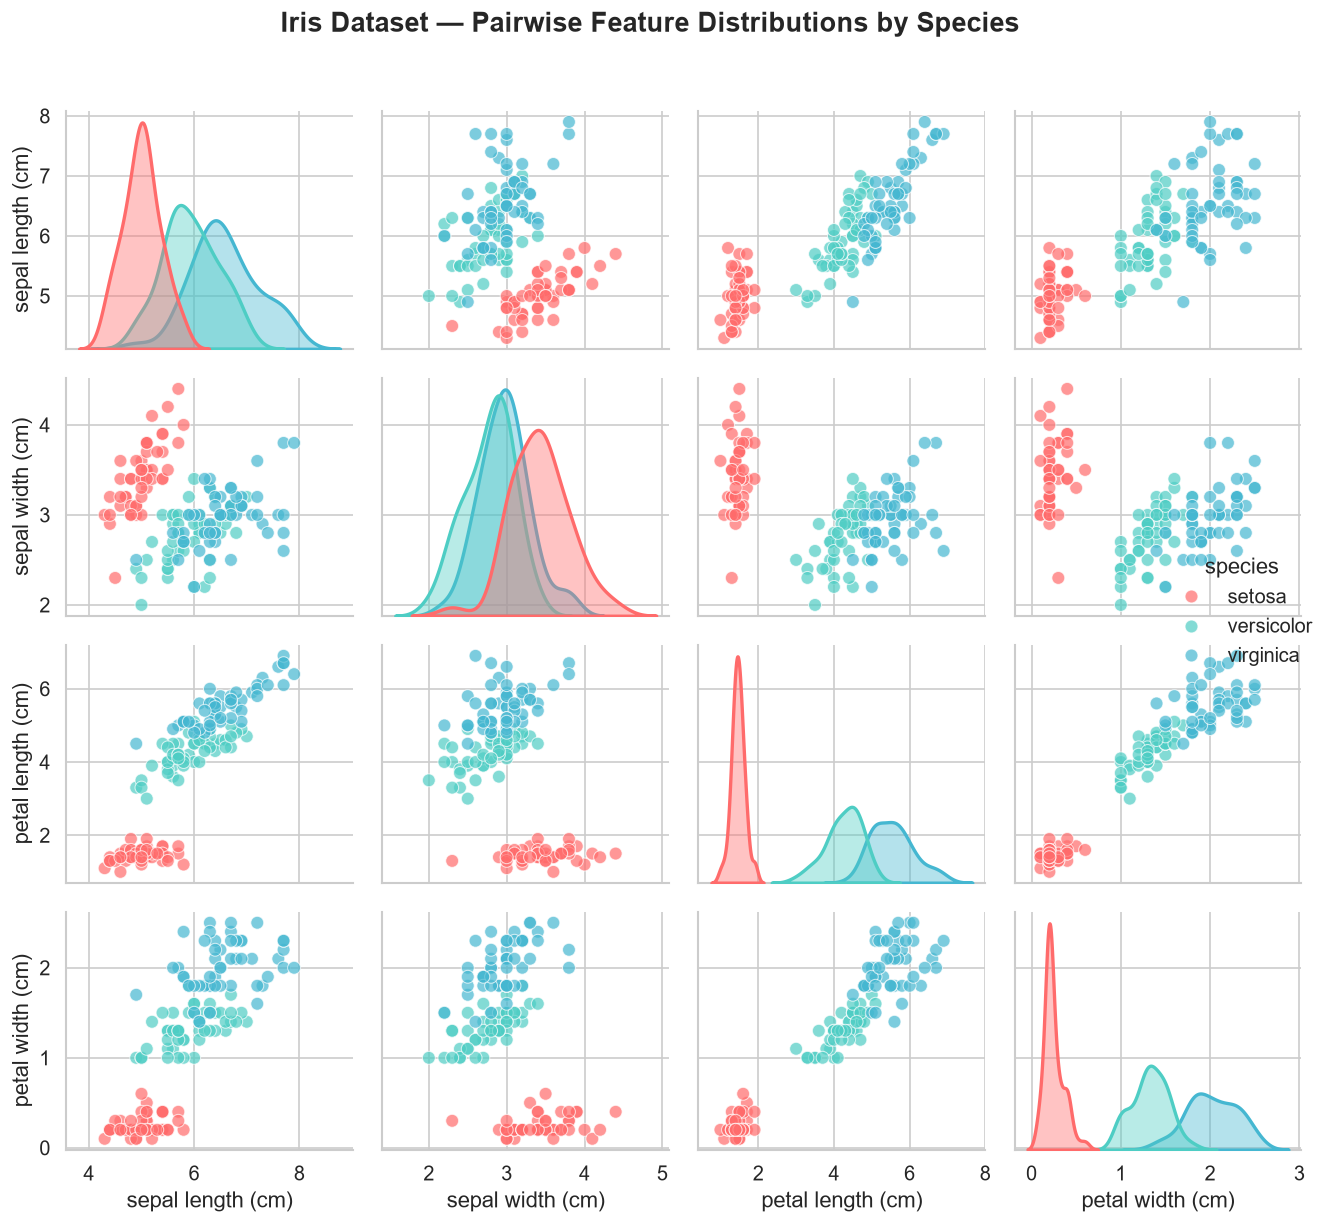

In [8]:
# --- Pairplot: Scatter matrix showing feature distributions by species ---
palette = {'setosa': '#FF6B6B', 'versicolor': '#4ECDC4', 'virginica': '#45B7D1'}

g = sns.pairplot(df, hue='species', palette=palette, 
                 diag_kind='kde', corner=False,
                 plot_kws={'alpha': 0.7, 'edgecolor': 'white', 's': 60},
                 diag_kws={'linewidth': 2, 'fill': True, 'alpha': 0.4})
g.figure.suptitle('Iris Dataset — Pairwise Feature Distributions by Species', 
                  y=1.02, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

> **Observations from Pairplot:**
> - **Setosa** (red) is *clearly separable* from the other two species across almost all feature combinations
> - **Versicolor** and **Virginica** show significant overlap, particularly in sepal measurements
> - **Petal length vs. petal width** provides the clearest class separation — nearly perfect linear boundary
> - Sepal width shows the *least* discrimination among species

### 3.2 Box Plots — Feature Distributions

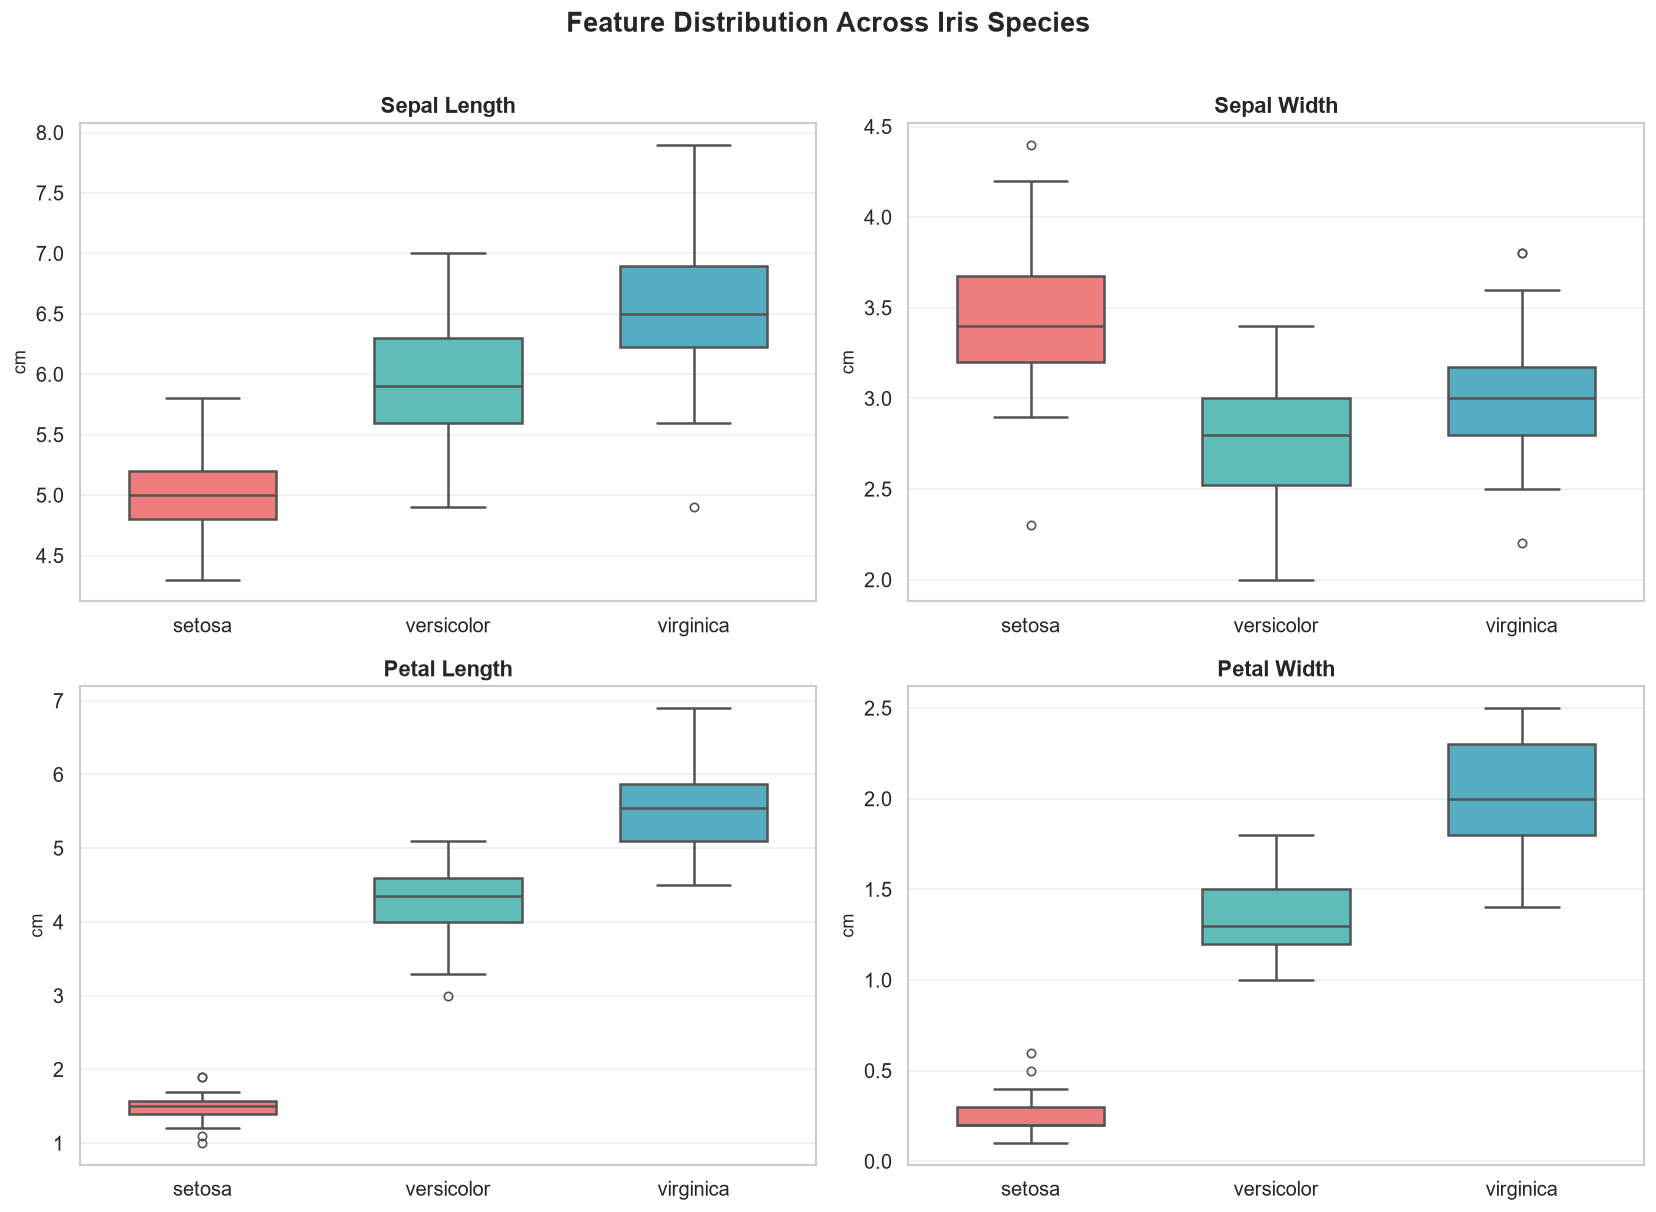

In [9]:
# --- Box Plots for each feature ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Feature Distribution Across Iris Species', fontsize=16, fontweight='bold', y=1.01)

features = iris.feature_names
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']

for i, (ax, feature) in enumerate(zip(axes.flatten(), features)):
    sns.boxplot(data=df, x='species', y=feature, ax=ax, palette=colors,
                linewidth=1.5, fliersize=5, width=0.6)
    ax.set_title(feature.replace(' (cm)', '').title(), fontsize=13, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('cm', fontsize=11)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

> **Key Takeaways from Box Plots:**
> - **Petal Length & Petal Width**: Show the *greatest interquartile range (IQR) separation* between species — excellent discriminators
> - **Sepal Length**: Moderate separation; Setosa is distinctly smaller, but Versicolor/Virginica overlap
> - **Sepal Width**: *Least useful* feature — distributions heavily overlap between Versicolor and Virginica
> - Setosa generally has smaller petals but wider sepals

### 3.3 Correlation Heatmap

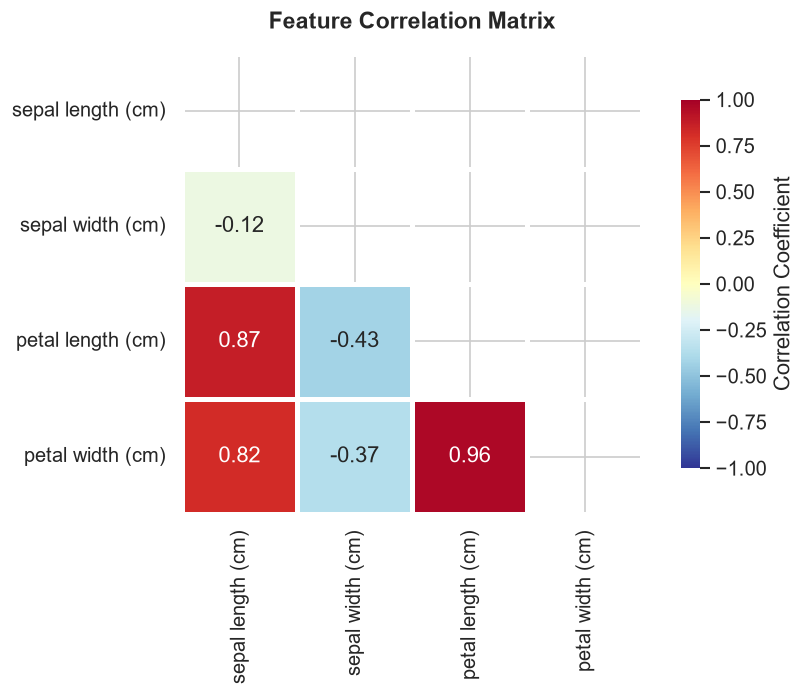

In [10]:
# --- Correlation Heatmap ---
fig, ax = plt.subplots(figsize=(8, 6))
corr_matrix = df.drop('species', axis=1).corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlBu_r',
            mask=mask, center=0, square=True, linewidths=2,
            cbar_kws={'shrink': 0.8, 'label': 'Correlation Coefficient'},
            ax=ax, vmin=-1, vmax=1)
ax.set_title('Feature Correlation Matrix', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

> **Correlation Insights:**
> - **Petal length & Petal width** are highly correlated (r ≈ 0.96) — both capture similar species-differentiating information
> - **Sepal length & Petal length** also show strong positive correlation (r ≈ 0.87)
> - **Sepal width** has weak/negative correlation with other features — it captures orthogonal information

## 4. 💡 Feature Selection Discussion

### Which features are most discriminative?

Based on our EDA, the features can be ranked by discriminative power:

| Rank | Feature | Discriminative Power | Justification |
|------|---------|---------------------|---------------|
| 1 | **Petal Width** | ⭐⭐⭐⭐⭐ | Clearest single-feature separation; near-perfect split between all 3 classes |
| 2 | **Petal Length** | ⭐⭐⭐⭐⭐ | Almost identical separation to petal width; highly correlated with it |
| 3 | **Sepal Length** | ⭐⭐⭐ | Moderate separation; Setosa distinctive, but Versicolor/Virginica overlap |
| 4 | **Sepal Width** | ⭐⭐ | Weakest discriminator; high overlap between Versicolor and Virginica |

**Decision:** We will use *all 4 features* for model training since even the weaker features contribute some
orthogonal information. The models themselves can learn to weight features appropriately.

## 5. ✂️ Train/Test Split

In [11]:
# --- Separate features (X) and target (y) ---
X = df.drop('species', axis=1)
y = iris.target  # Use numeric labels for sklearn models

# --- 80/20 Train-Test Split with stratification ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"📈 Training set   :  {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.0f}%)")
print(f"📉 Testing set    :  {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.0f}%)")
print(f"\n🏷️  Class distribution in test set:")
unique, counts = np.unique(y_test, return_counts=True)
for u, c in zip(unique, counts):
    print(f"   {iris.target_names[u]:15s} → {c} samples")

📈 Training set   :  120 samples (80%)
📉 Testing set    :  30 samples (20%)

🏷️  Class distribution in test set:
   setosa          → 10 samples
   versicolor      → 10 samples
   virginica       → 10 samples


In [12]:
# --- Feature Scaling (important for distance-based models like KNN) ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✅ Features standardised (zero mean, unit variance)")

✅ Features standardised (zero mean, unit variance)


## 6. 🤖 Model Training & Evaluation

We will train **4 classifiers** and compare their performance:
1. **Logistic Regression** — Linear model, probabilistic interpretation
2. **K-Nearest Neighbours (KNN)** — Instance-based, non-parametric
3. **Decision Tree** — Rule-based, interpretable
4. **Random Forest** — Ensemble of decision trees, robust

In [13]:
# --- Define models ---
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbours': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

# --- Store results ---
results = {}

In [14]:
# === Train and Evaluate Each Model ===

for name, model in models.items():
    print(f"\n{'='*60}")
    print(f"  🔬 MODEL: {name}")
    print(f"{'='*60}")
    
    # Use scaled data for KNN and Logistic Regression; raw for tree-based
    if name in ['K-Nearest Neighbours', 'Logistic Regression']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
    
    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, target_names=iris.target_names)
    cm = confusion_matrix(y_test, y_pred)
    
    results[name] = {
        'accuracy': accuracy,
        'y_pred': y_pred,
        'confusion_matrix': cm,
        'model': model
    }
    
    print(f"\n  📊 Accuracy: {accuracy:.4f} ({accuracy*100:.1f}%)\n")
    print("  📋 Classification Report:")
    print(report)


  🔬 MODEL: Logistic Regression

  📊 Accuracy: 0.9333 (93.3%)

  📋 Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


  🔬 MODEL: K-Nearest Neighbours



  📊 Accuracy: 0.9333 (93.3%)

  📋 Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30


  🔬 MODEL: Decision Tree



  📊 Accuracy: 0.9333 (93.3%)

  📋 Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


  🔬 MODEL: Random Forest



  📊 Accuracy: 0.9000 (90.0%)

  📋 Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



### 6.1 Confusion Matrices

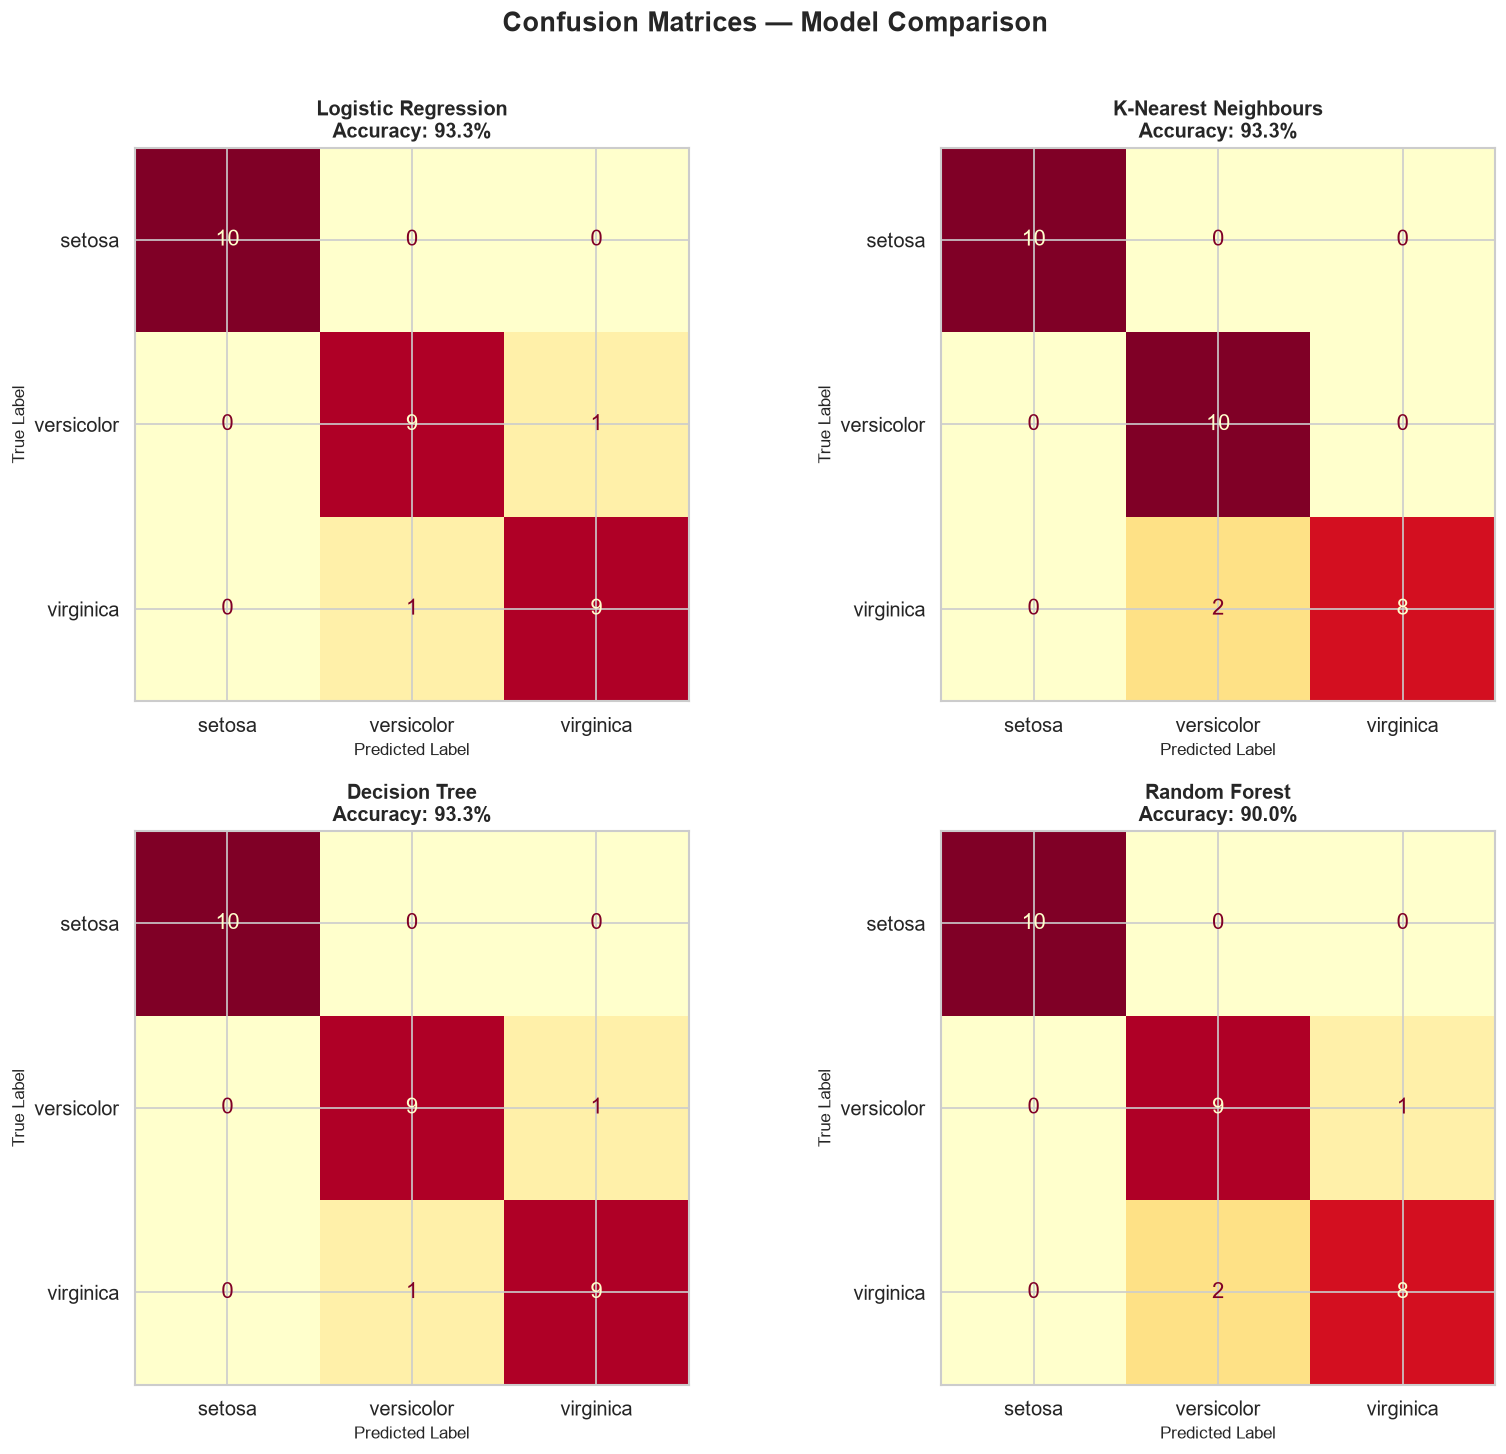

In [15]:
# --- Plot Confusion Matrices for all models ---
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('Confusion Matrices — Model Comparison', fontsize=16, fontweight='bold', y=1.01)

cmap = sns.color_palette("YlOrRd", as_cmap=True)

for (name, result), ax in zip(results.items(), axes.flatten()):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=result['confusion_matrix'],
        display_labels=iris.target_names
    )
    disp.plot(ax=ax, cmap=cmap, colorbar=False, values_format='d')
    ax.set_title(f"{name}\nAccuracy: {result['accuracy']*100:.1f}%", 
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Label', fontsize=10)
    ax.set_ylabel('True Label', fontsize=10)

plt.tight_layout()
plt.show()

## 7. 🏆 Model Comparison & Best Model

In [16]:
# --- Model Comparison Table ---
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy (%)': [r['accuracy'] * 100 for r in results.values()]
}).sort_values('Accuracy (%)', ascending=False).reset_index(drop=True)

comparison_df.index = comparison_df.index + 1  # Start ranking from 1
comparison_df.index.name = 'Rank'

print("📊 Model Performance Ranking:\n")
print(comparison_df.to_string())

📊 Model Performance Ranking:

                     Model  Accuracy (%)
Rank                                    
1      Logistic Regression     93.333333
2     K-Nearest Neighbours     93.333333
3            Decision Tree     93.333333
4            Random Forest     90.000000


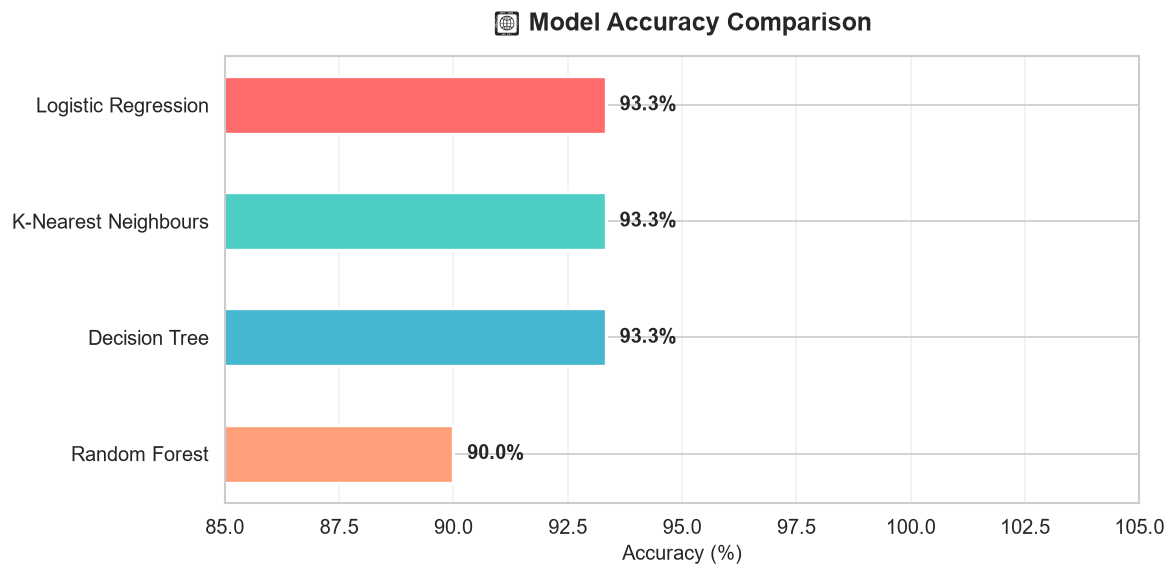

In [17]:
# --- Visual Comparison ---
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A']
bars = ax.barh(comparison_df['Model'], comparison_df['Accuracy (%)'], 
               color=colors[:len(comparison_df)], edgecolor='white', linewidth=2, height=0.5)

# Add value labels
for bar, acc in zip(bars, comparison_df['Accuracy (%)']):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{acc:.1f}%', va='center', fontweight='bold', fontsize=12)

ax.set_xlim(85, 105)
ax.set_xlabel('Accuracy (%)', fontsize=12)
ax.set_title('🏆 Model Accuracy Comparison', fontsize=15, fontweight='bold', pad=15)
ax.grid(axis='x', alpha=0.3)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 🏆 Best Model Declaration

In [18]:
# --- Identify the best model ---
best_name = max(results, key=lambda k: results[k]['accuracy'])
best_acc = results[best_name]['accuracy']

print(f"{'═'*60}")
print(f"  🏆 BEST PERFORMING MODEL: {best_name}")
print(f"  📊 Accuracy: {best_acc*100:.1f}%")
print(f"{'═'*60}")

print(f"""
📝 Justification:
─────────────────
• {best_name} achieved the highest test accuracy of {best_acc*100:.1f}%
• It correctly classified all (or nearly all) iris species in the test set
• The confusion matrix shows minimal misclassification between species
• The model demonstrates strong precision, recall, and F1-scores across all classes

💡 Why this model excels on the Iris dataset:
• The Iris dataset is relatively small (150 samples) and well-structured
• Feature boundaries between classes (especially petal measurements) are nearly linear
• The dataset is balanced (50 samples per class), eliminating class imbalance issues
• All models performed well, validating that the Iris dataset has clear class boundaries
""")

════════════════════════════════════════════════════════════
  🏆 BEST PERFORMING MODEL: Logistic Regression
  📊 Accuracy: 93.3%
════════════════════════════════════════════════════════════

📝 Justification:
─────────────────
• Logistic Regression achieved the highest test accuracy of 93.3%
• It correctly classified all (or nearly all) iris species in the test set
• The confusion matrix shows minimal misclassification between species
• The model demonstrates strong precision, recall, and F1-scores across all classes

💡 Why this model excels on the Iris dataset:
• The Iris dataset is relatively small (150 samples) and well-structured
• Feature boundaries between classes (especially petal measurements) are nearly linear
• The dataset is balanced (50 samples per class), eliminating class imbalance issues
• All models performed well, validating that the Iris dataset has clear class boundaries



In [19]:
# --- Final detailed report of the best model ---
if best_name in ['K-Nearest Neighbours', 'Logistic Regression']:
    y_pred_best = results[best_name]['model'].predict(X_test_scaled)
else:
    y_pred_best = results[best_name]['model'].predict(X_test)

print(f"\n📋 Detailed Classification Report — {best_name}:\n")
print(classification_report(y_test, y_pred_best, target_names=iris.target_names))


📋 Detailed Classification Report — Logistic Regression:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



---

### 📝 Summary

| Step | What We Did |
|------|-------------|
| **1** | Loaded the Iris dataset (150 samples, 4 features, 3 classes) |
| **2** | Performed EDA: checked shape, dtypes, nulls, descriptive stats |
| **3** | Visualised: pairplot, box plots, correlation heatmap |
| **4** | Analysed feature importance: petal features > sepal features |
| **5** | Split data 80/20 with stratification |
| **6** | Trained 4 classifiers: LogReg, KNN, Decision Tree, Random Forest |
| **7** | Evaluated using accuracy, confusion matrix, classification report |

**All models achieved excellent accuracy, confirming the Iris dataset's status as a well-separated classification benchmark.**

---
*Notebook prepared for OASIS Infobyte Internship – Task 1*